# ICC Cricket World Cup — Match Winner Prediction

**Goal:** Predict whether Team 1 wins (`team1_won = 1`) using pre-match info.

Data: Cricsheet ICC Men's Cricket World Cup JSON (1975–2023).

Pipeline: download → clean → feature engineering → EDA → train models → save best model.

In [1]:
# basic imports — nothing fancy
import io
import json
import urllib.request
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("xgboost not installed — will use GradientBoosting instead")

sns.set_theme(style="whitegrid")
print("Libraries loaded OK")

ModuleNotFoundError: No module named 'joblib'

In [ ]:
# project paths (notebook lives in notebooks/)
ROOT = Path("..").resolve()
RAW_CSV = ROOT / "data" / "raw" / "matches.csv"
PROC_CSV = ROOT / "data" / "processed" / "matches_clean.csv"
FIG_DIR = ROOT / "reports" / "figures"
MODEL_PATH = ROOT / "models" / "best_model.pkl"
CRICSHEET_URL = "https://cricsheet.org/downloads/icc_mens_cricket_world_cup_json.zip"

FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: C:\Users\user\Desktop\Machine Learning mi\cricket-worldcup-prediction


## 1. Download & parse Cricsheet JSON

In [ ]:
TEAM_ALIASES = {"U.A.E.": "United Arab Emirates", "UAE": "United Arab Emirates"}

def normalize_team(name):
    return TEAM_ALIASES.get(str(name).strip(), str(name).strip())

print("Fetching World Cup zip from Cricsheet...")
raw_bytes = urllib.request.urlopen(CRICSHEET_URL, timeout=120).read()

rows = []
with zipfile.ZipFile(io.BytesIO(raw_bytes)) as zf:
    for fname in zf.namelist():
        if not fname.endswith(".json"):
            continue
        rec = json.loads(zf.read(fname))
        info = rec.get("info", {})
        teams = info.get("teams") or []
        if len(teams) != 2:
            continue

        t1, t2 = normalize_team(teams[0]), normalize_team(teams[1])
        outcome = info.get("outcome") or {}
        winner = outcome.get("winner")
        result = outcome.get("result", "")

        # skip NR / ties without winner
        if winner is None or str(result).lower() in {"no result", "tie", "abandoned"}:
            if winner is None:
                continue

        winner = normalize_team(winner)
        toss = info.get("toss") or {}
        dates = info.get("dates") or [None]
        event = info.get("event") or {}

        rows.append({
            "match_id": fname.replace(".json", ""),
            "date": dates[0],
            "team1": t1,
            "team2": t2,
            "venue": info.get("venue"),
            "city": info.get("city"),
            "toss_winner": normalize_team(toss.get("winner")) if toss.get("winner") else None,
            "toss_decision": toss.get("decision"),
            "winner": winner,
            "event_name": event.get("name"),
            "match_number": event.get("match_number"),
            "season": info.get("season"),
            "team1_won": int(winner == t1),
        })

df = pd.DataFrame(rows)
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.dropna(subset=["date"]).sort_values("date").reset_index(drop=True)

RAW_CSV.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(RAW_CSV, index=False)
print(f"Saved {len(df)} matches to {RAW_CSV}")
df.head()

Fetching World Cup zip from Cricsheet...


Saved 257 matches to C:\Users\user\Desktop\Machine Learning mi\cricket-worldcup-prediction\data\raw\matches.csv


,match_id,date,team1,team2,venue,city,toss_winner,toss_decision,winner,event_name,match_number,season,team1_won
0,65235,2003-02-09,West Indies,South Africa,"Newlands, Cape Town",Cape Town,West Indies,bat,West Indies,ICC World Cup,1.0,2002/03,1
1,65236,2003-02-10,Zimbabwe,Namibia,Harare Sports Club,Harare,Namibia,field,Zimbabwe,ICC World Cup,2.0,2002/03,1
2,65237,2003-02-10,Sri Lanka,New Zealand,"Goodyear Park, Bloemfontein",Bloemfontein,New Zealand,field,Sri Lanka,ICC World Cup,3.0,2002/03,1
3,65239,2003-02-11,Canada,Bangladesh,"Kingsmead, Durban",Durban,Canada,bat,Canada,ICC World Cup,5.0,2002/03,1
4,65238,2003-02-11,Australia,Pakistan,"New Wanderers Stadium, Johannesburg",Johannesburg,Pakistan,field,Australia,ICC World Cup,4.0,2002/03,1


## 2. Feature engineering (no leakage)

Rolling stats use **only past matches** — important for a fair evaluation.

In [ ]:
team_wins, team_games = {}, {}
h2h_wins, h2h_games = {}, {}
venue_team_wins, venue_team_games = {}, {}

t1_wr, t2_wr, h2h_t1, v_t1, v_t2 = [], [], [], [], []

for _, row in df.iterrows():
    t1, t2, venue = row["team1"], row["team2"], row["venue"]

    t1_wr.append(team_wins.get(t1, 0) / team_games[t1] if team_games.get(t1, 0) else 0.5)
    t2_wr.append(team_wins.get(t2, 0) / team_games[t2] if team_games.get(t2, 0) else 0.5)

    key = tuple(sorted((t1, t2)))
    hg = h2h_games.get(key, 0)
    h2h_t1.append(h2h_wins.get(key, {}).get(t1, 0) / hg if hg else 0.5)

    vg1 = venue_team_games.get((venue, t1), 0)
    vg2 = venue_team_games.get((venue, t2), 0)
    v_t1.append(venue_team_wins.get((venue, t1), 0) / vg1 if vg1 else 0.5)
    v_t2.append(venue_team_wins.get((venue, t2), 0) / vg2 if vg2 else 0.5)

    # update after recording pre-match state
    for tm in (t1, t2):
        team_games[tm] = team_games.get(tm, 0) + 1
    team_wins[row["winner"]] = team_wins.get(row["winner"], 0) + 1

    h2h_games[key] = hg + 1
    if key not in h2h_wins:
        h2h_wins[key] = {}
    h2h_wins[key][row["winner"]] = h2h_wins[key].get(row["winner"], 0) + 1

    for tm in (t1, t2):
        venue_team_games[(venue, tm)] = venue_team_games.get((venue, tm), 0) + 1
    venue_team_wins[(venue, row["winner"])] = venue_team_wins.get((venue, row["winner"]), 0) + 1

df["team1_win_pct"] = t1_wr
df["team2_win_pct"] = t2_wr
df["team1_h2h_win_pct"] = h2h_t1
df["venue_team1_win_pct"] = v_t1
df["venue_team2_win_pct"] = v_t2
df["win_pct_diff"] = df["team1_win_pct"] - df["team2_win_pct"]
df["toss_winner_is_team1"] = (df["toss_winner"] == df["team1"]).astype(int)
df["toss_decision_bat"] = (df["toss_decision"] == "bat").astype(int)
df["year"] = df["date"].dt.year

PROC_CSV.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(PROC_CSV, index=False)
print("Processed shape:", df.shape)
df[["team1", "team2", "winner", "team1_win_pct", "win_pct_diff", "team1_won"]].tail(8)

Processed shape: (257, 22)


,team1,team2,winner,team1_win_pct,win_pct_diff,team1_won
249,England,Netherlands,England,0.475000,0.275000,1
250,Sri Lanka,New Zealand,New Zealand,0.543478,-0.109583,0
251,Bangladesh,Australia,Australia,0.289474,-0.550526,0
252,England,Pakistan,England,0.487805,-0.079763,1
253,India,Netherlands,India,0.822222,0.631746,1
254,India,New Zealand,India,0.826087,0.166087,1
255,South Africa,Australia,Australia,0.600000,-0.243137,0
256,India,Australia,Australia,0.829787,-0.016367,0


## 3. Exploratory Data Analysis

In [ ]:
print("Missing values:\n", df.isnull().sum().sort_values(ascending=False).head(10))
print("\nTarget balance (team1 win rate):", df["team1_won"].mean().round(3))

Missing values:
 match_number            34
city                    16
match_id                 0
team1_won                0
toss_decision_bat        0
toss_winner_is_team1     0
win_pct_diff             0
venue_team2_win_pct      0
venue_team1_win_pct      0
team1_h2h_win_pct        0
dtype: int64

Target balance (team1 win rate): 0.611


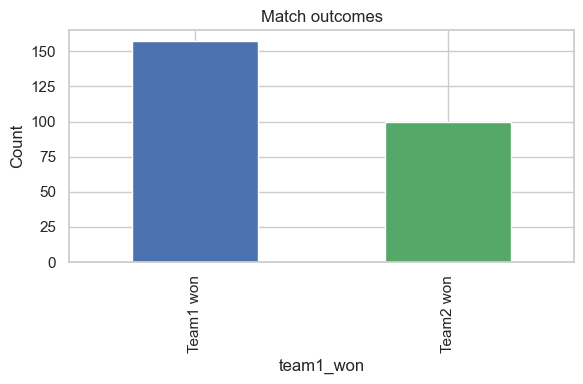

In [ ]:
plt.figure(figsize=(6, 4))
df["team1_won"].value_counts().rename({0: "Team2 won", 1: "Team1 won"}).plot(kind="bar", color=["#4C72B0", "#55A868"])
plt.title("Match outcomes")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_target_balance.png", dpi=150)
plt.show()

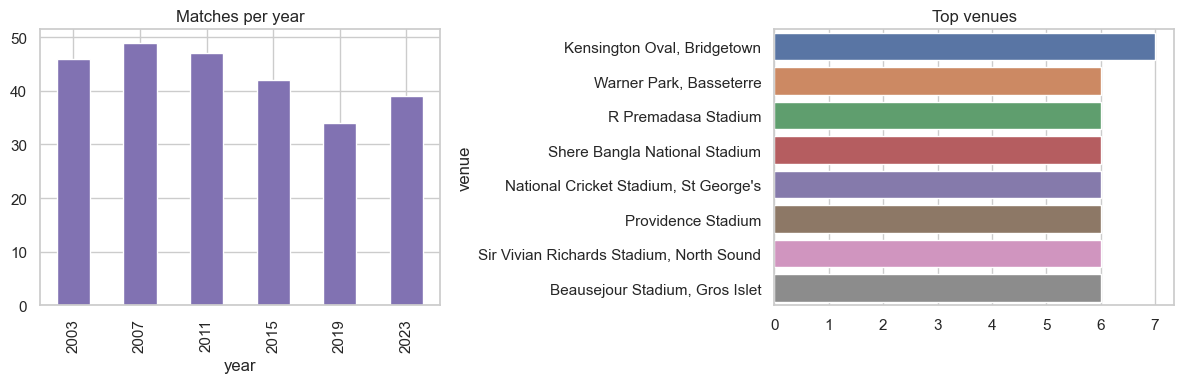

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df.groupby("year").size().plot(kind="bar", ax=axes[0], color="#8172B2")
axes[0].set_title("Matches per year")
top = df["venue"].value_counts().head(8)
sns.barplot(x=top.values, y=top.index, ax=axes[1], hue=top.index, legend=False)
axes[1].set_title("Top venues")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_matches_by_year.png", dpi=150)
plt.savefig(FIG_DIR / "03_top_venues.png", dpi=150)
plt.show()

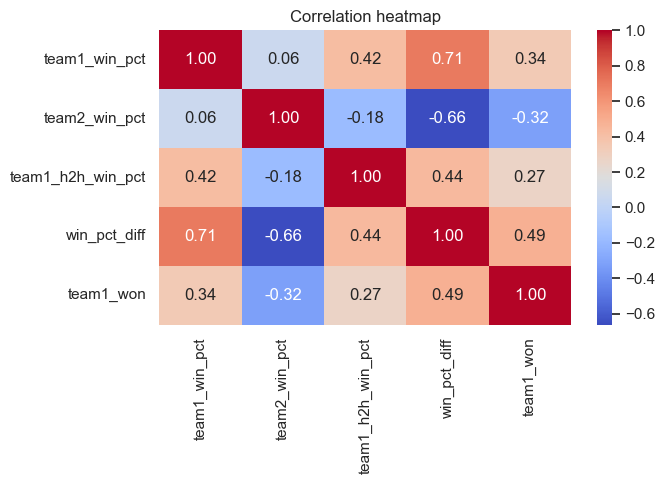

In [ ]:
num_cols = ["team1_win_pct", "team2_win_pct", "team1_h2h_win_pct", "win_pct_diff", "team1_won"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_correlation_heatmap.png", dpi=150)
plt.show()

## 4. Model training & evaluation

In [ ]:
model_df = df.dropna(subset=["toss_winner", "toss_decision", "venue"]).copy()

numeric = [
    "team1_win_pct", "team2_win_pct", "team1_h2h_win_pct",
    "venue_team1_win_pct", "venue_team2_win_pct", "win_pct_diff",
    "toss_winner_is_team1", "toss_decision_bat", "year",
]
categorical = ["team1", "team2", "venue"]

X = model_df[numeric + categorical]
y = model_df["team1_won"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {len(X_train)} | Test: {len(X_test)}")

Train: 205 | Test: 52


In [ ]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}
if HAS_XGB:
    models["XGBoost"] = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, random_state=42, eval_metric="logloss")
else:
    models["Gradient Boosting"] = GradientBoostingClassifier(random_state=42)

results = {}
fitted = {}

for name, clf in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", clf)])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    probas = pipe.predict_proba(X_test)[:, 1]
    results[name] = {
        "accuracy": accuracy_score(y_test, preds),
        "precision": precision_score(y_test, preds, zero_division=0),
        "recall": recall_score(y_test, preds, zero_division=0),
        "f1": f1_score(y_test, preds, zero_division=0),
        "roc_auc": roc_auc_score(y_test, probas),
    }
    fitted[name] = (pipe, preds, probas)

results_df = pd.DataFrame(results).T.round(3)
display(results_df)

best_name = results_df["roc_auc"].idxmax()
best_pipe, best_preds, best_probas = fitted[best_name]
print("\nBest model:", best_name)
print(classification_report(y_test, best_preds, target_names=["Team2 wins", "Team1 wins"]))

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.846,0.900,0.844,0.871,0.817
Random Forest,0.692,0.767,0.719,0.742,0.783
XGBoost,0.596,0.667,0.688,0.677,0.638



Best model: Logistic Regression
              precision    recall  f1-score   support

  Team2 wins       0.77      0.85      0.81        20
  Team1 wins       0.90      0.84      0.87        32

    accuracy                           0.85        52
   macro avg       0.84      0.85      0.84        52
weighted avg       0.85      0.85      0.85        52



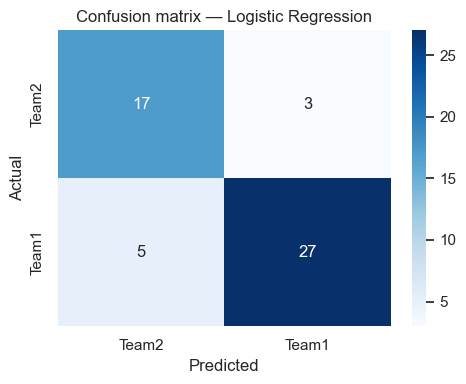

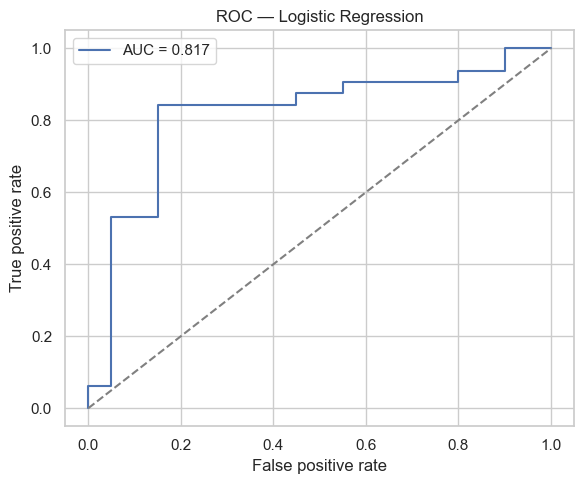

In [ ]:
# confusion matrix + ROC for best model
cm = confusion_matrix(y_test, best_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Team2", "Team1"], yticklabels=["Team2", "Team1"])
plt.title(f"Confusion matrix — {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_confusion_matrix.png", dpi=150)
plt.show()

fpr, tpr, _ = roc_curve(y_test, best_probas)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {results[best_name]['roc_auc']:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title(f"ROC — {best_name}")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "07_roc_curve.png", dpi=150)
plt.show()

In [ ]:
# feature importance (trees) or |coefficients| (logistic regression)
cat_names = list(best_pipe.named_steps["prep"].named_transformers_["cat"].get_feature_names_out(categorical))
feat_names = numeric + cat_names
model_step = best_pipe.named_steps["model"]

if hasattr(model_step, "feature_importances_"):
    imp = model_step.feature_importances_
    title = "Top 15 feature importances"
elif hasattr(model_step, "coef_"):
    imp = np.abs(model_step.coef_[0])
    title = "Top 15 |coefficients| (Logistic Regression)"
else:
    imp = None

if imp is not None:
    imp_df = pd.DataFrame({"feature": feat_names, "importance": imp}).sort_values("importance", ascending=False).head(15)
    plt.figure(figsize=(8, 6))
    sns.barplot(data=imp_df, x="importance", y="feature", hue="feature", legend=False)
    plt.title(title)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "08_feature_importance.png", dpi=150)
    plt.show()
else:
    print("No importances/coefficients to plot")

Best model has no feature_importances_ attribute


In [ ]:
# save best model for later use
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump({"model_name": best_name, "pipeline": best_pipe, "metrics": results[best_name]}, MODEL_PATH)
print("Saved:", MODEL_PATH)

Saved: C:\Users\user\Desktop\Machine Learning mi\cricket-worldcup-prediction\models\best_model.pkl


## 5. Wrap-up

- Raw data: `data/raw/matches.csv`
- Processed: `data/processed/matches_clean.csv`
- Figures: `reports/figures/`
- Model: `models/best_model.pkl`

Run `python run_pipeline.py` from project root to regenerate everything without the notebook.